In [1]:
import sys
sys.path.append('/glade/u/home/manishrv/documents/croc/dev/CrocoLens')
%load_ext autoreload
%autoreload 2
from CrocoLens.obc import OBC
from CrocoLens.regional_domain import RegionalDomain
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import cartopy.crs as ccrs


RuntimeError: No mappable was found to use for colorbar creation. First define a mappable such as an image (with imshow) or a contour set (with contourf).

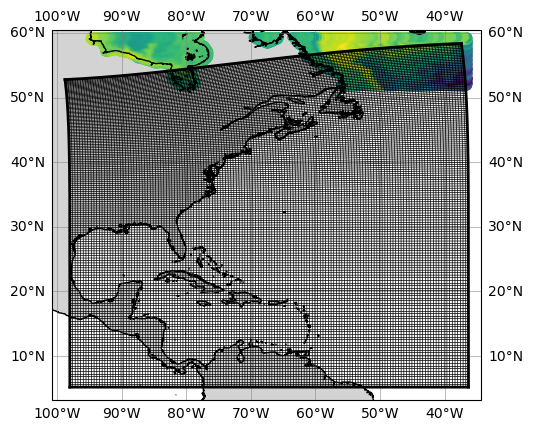

In [2]:
rd = RegionalDomain("/glade/u/home/manishrv/documents/croc/mom_input/gfdl_copy.4.n3b/hgrid.nc")
ax = rd.plot_map()
for seg in ["north", "south", "east", "west"]:
    ds = xr.open_dataset(f"/glade/u/home/manishrv/documents/croc/dev/bgc/cesm_downscaling/raw_data/PO4_{seg}_unprocessed.nc")
    scatter = ax.scatter(
                ds["TLONG"],
                ds["TLAT"],
                c=ds["PO4"][0][0],
                transform=ccrs.PlateCarree()
            )
    plt.colorbar()



/glade/work/manishrv/conda-envs/CrocoDash/lib/python3.12/site-packages/xarray/namedarray/core.py:487: UserWarning: Duplicate dimension names present: dimensions {'nx_segment_002'} appear more than once in dims=('time', 'z_t', 'nx_segment_002', 'nx_segment_002'). We do not yet support duplicate dimension names, but we do allow initial construction of the object. We recommend you rename the dims immediately to become distinct, as most xarray functionality is likely to fail silently if you do not. To rename the dimensions you will need to set the ``.dims`` attribute of each variable, ``e.g. var.dims=('x0', 'x1')``.
  warnings.warn(
/glade/work/manishrv/conda-envs/CrocoDash/lib/python3.12/site-packages/xarray/namedarray/core.py:487: UserWarning: Duplicate dimension names present: dimensions {'nx_segment_002'} appear more than once in dims=('time', 'z_t', 'nx_segment_002', 'nx_segment_002'). We do not yet support duplicate dimension names, but we do allow initial construction of the object.

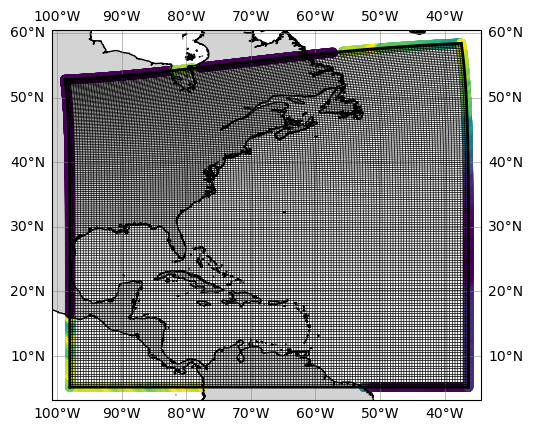

In [14]:
rd = RegionalDomain("/glade/u/home/manishrv/documents/croc/mom_input/gfdl_copy.4.n3b/hgrid.nc")
ax = rd.plot_map()
for seg in ["north", "south", "east", "west"]:
    ds = xr.open_dataset(f"/glade/u/home/manishrv/documents/croc/dev/bgc/cesm_downscaling/regridded_data/PO4_{seg}_regridded.nc")
    
    if seg in ["east","west"]:
        ds.variables["__xarray_dataarray_variable__"].dims = ('time', 'z_t', 'interest', "dummy")
        vals = ds.__xarray_dataarray_variable__[0,0,:,0]
    else:
        ds.variables["__xarray_dataarray_variable__"].dims = ('time', 'z_t', 'dummy', "interest")
        vals = ds.__xarray_dataarray_variable__[0,0,0,:]

    scatter = ax.scatter(
                ds["lon"],
                ds["lat"],
                c=vals,
                transform=ccrs.PlateCarree()
            )


/glade/u/home/manishrv/documents/croc/dev/CrocoLens/CrocoLens/obc.py:67: RuntimeWarning: Converting a CFTimeIndex with dates from a non-standard calendar, 'noleap', to a pandas.DatetimeIndex, which uses dates from the standard calendar.  This may lead to subtle errors in operations that depend on the length of time between dates.
  time_range = time.to_datetimeindex()
/glade/u/home/manishrv/documents/croc/dev/CrocoLens/CrocoLens/obc.py:67: RuntimeWarning: Converting a CFTimeIndex with dates from a non-standard calendar, 'noleap', to a pandas.DatetimeIndex, which uses dates from the standard calendar.  This may lead to subtle errors in operations that depend on the length of time between dates.
  time_range = time.to_datetimeindex()
/glade/u/home/manishrv/documents/croc/dev/CrocoLens/CrocoLens/obc.py:67: RuntimeWarning: Converting a CFTimeIndex with dates from a non-standard calendar, 'noleap', to a pandas.DatetimeIndex, which uses dates from the standard calendar.  This may lead to sub

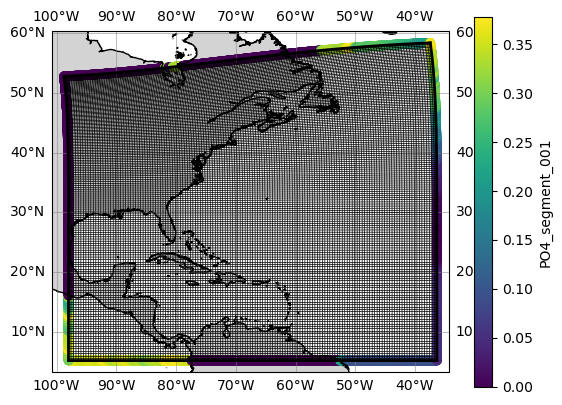

In [15]:
rd.add_obc_segment("/glade/u/home/manishrv/documents/croc/dev/bgc/cesm_downscaling/processed_data/PO4_obc_segment_002.nc")
rd.add_obc_segment("/glade/u/home/manishrv/documents/croc/dev/bgc/cesm_downscaling/processed_data/PO4_obc_segment_001.nc")
rd.add_obc_segment("/glade/u/home/manishrv/documents/croc/dev/bgc/cesm_downscaling/processed_data/PO4_obc_segment_003.nc")
rd.add_obc_segment("/glade/u/home/manishrv/documents/croc/dev/bgc/cesm_downscaling/processed_data/PO4_obc_segment_004.nc")
ax = rd.plot_map()
ax = rd.obc_segments["001"].plot_obc("PO4", ax= ax)
ax = rd.obc_segments["002"].plot_obc("PO4", ax= ax, colorbar=False)
ax = rd.obc_segments["003"].plot_obc("PO4", ax= ax, colorbar=False)
ax = rd.obc_segments["004"].plot_obc("PO4", ax= ax, colorbar=False)
plt.show()